<a href="https://colab.research.google.com/github/HamzaEric/caltech101-transfer-learning/blob/main/Notebooks/Baseline_vs_Feature_Extracted_vs_Fine_Tuned.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
import os, json
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from pathlib import Path
import zipfile
import shutil
import random
import torch.nn.functional as F
import time
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,f1_score,precision_recall_fscore_support
from PIL import Image
import pandas as pd
from torchvision.utils import make_grid

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [2]:
def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

# Pretrained Baseline

In [3]:
base_model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
num_features = base_model.fc.in_features

# Pretrained baseline:
model_pretrained = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for p in model_pretrained.parameters():
    p.requires_grad = False   # 0 trainable params

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 165MB/s]


# Feature Extracted Model

In [6]:
# Feature-extracted model
model_feature = models.resnet18(weights=None)
model_feature.fc = nn.Linear(num_features, 102)
model_feature.load_state_dict(
    torch.load("/content/drive/MyDrive/checkpoints/resnet18_feature_extraction.pth", weights_only=False, map_location="cpu")
)


for p in model_feature.parameters():
    p.requires_grad = False

# Unfreeze only classifier
for p in model_feature.fc.parameters():
    p.requires_grad = True

# Fine-Tuned Model

In [7]:
# Fine-tuned model
model_finetuned = models.resnet18(weights=None)
model_finetuned.fc = nn.Linear(num_features, 102)
model_finetuned.load_state_dict(
    torch.load("/content/drive/MyDrive/checkpoints/resnet18_finetuned.pth", weights_only=False, map_location="cpu")
)


for p in model_finetuned.parameters():
    p.requires_grad = False

# Unfreeze only layer4 and head
for p in model_finetuned.layer4.parameters():
    p.requires_grad = True
for p in model_finetuned.fc.parameters():
    p.requires_grad = True

In [8]:
def print_trainable_layers(model, name):
    trainable_layers = [n for n, p in model.named_parameters() if p.requires_grad]
    print(f"\nModel: {name}")
    print(f"Trainable layers: {len(trainable_layers)} out of {len(list(model.parameters()))}")
    print("Example trainable params:",
          trainable_layers[-5:] if trainable_layers else "None")

print_trainable_layers(model_pretrained, "Pretrained (ImageNet)")
print_trainable_layers(model_feature, "Feature-Extracted (NB02)")
print_trainable_layers(model_finetuned, "Fine-Tuned (NB03)")

# === Count parameters ===
for name, mdl in zip(
    ["Pretrained", "Feature-Extracted", "Fine-Tuned"],
    [model_pretrained, model_feature, model_finetuned]
):
    total, trainable = count_params(mdl)
    print(f"{name:18s} | Total: {total/1e6:.2f}M | "
          f"Trainable: {trainable/1e6:.4f}M | "
          f"Frozen: {(total-trainable)/1e6:.4f}M")


Model: Pretrained (ImageNet)
Trainable layers: 0 out of 62
Example trainable params: None

Model: Feature-Extracted (NB02)
Trainable layers: 2 out of 62
Example trainable params: ['fc.weight', 'fc.bias']

Model: Fine-Tuned (NB03)
Trainable layers: 17 out of 62
Example trainable params: ['layer4.1.conv2.weight', 'layer4.1.bn2.weight', 'layer4.1.bn2.bias', 'fc.weight', 'fc.bias']
Pretrained         | Total: 11.69M | Trainable: 0.0000M | Frozen: 11.6895M
Feature-Extracted  | Total: 11.23M | Trainable: 0.0523M | Frozen: 11.1765M
Fine-Tuned         | Total: 11.23M | Trainable: 8.4461M | Frozen: 2.7828M


In [12]:
zip_path = '/content/drive/MyDrive/caltech-101.zip'
extract_path = '/content'


os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
    print(f"Successfully extracted all files to: {extract_path}")

Successfully extracted all files to: /content


In [13]:
!tar -xzf /content/caltech-101/101_ObjectCategories.tar.gz -C /content/caltech-101/

In [16]:
source_dir = Path('/content/caltech-101/101_ObjectCategories')
output_dir = Path('/content/caltech-splits')

# Split ratios
train_ratio = 0.70
val_ratio = 0.15


random.seed(42)  # For reproducible splits

for class_folder in source_dir.iterdir():
    if class_folder.is_dir():
        class_name = class_folder.name

        # Get all valid image files
        images = [f for f in class_folder.iterdir() if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]
        random.shuffle(images)

        n_total = len(images)
        n_train = int(n_total * train_ratio)
        n_val = int(n_total * val_ratio)

        train_imgs = images[:n_train]
        val_imgs = images[n_train:n_train + n_val]
        test_imgs = images[n_train + n_val:]

        # Create destination folders
        for split_name, split_imgs in [('train', train_imgs), ('val', val_imgs), ('test', test_imgs)]:
            split_class_dir = output_dir / split_name / class_name
            split_class_dir.mkdir(parents=True, exist_ok=True)

            for img_path in split_imgs:
                shutil.copy(img_path, split_class_dir / img_path.name)

print(f"Dataset successfully split and saved to: {output_dir}")

Dataset successfully split and saved to: /content/caltech-splits


In [17]:
DATA_ROOT = Path("/content/caltech-splits")
CKPT_DIR  = Path("/content/drive/MyDrive/checkpoints")
MAP_PATH      = CKPT_DIR / "class_to_idx.pth"

assert DATA_ROOT.exists(), f"Dataset not found at {DATA_ROOT}"
assert (DATA_ROOT / "test").exists(), f"Test split missing at {DATA_ROOT/'test'}"
assert MAP_PATH.exists(), f"class_to_idx mapping not found at {MAP_PATH}"

class_to_idx_saved = torch.load(MAP_PATH, weights_only=False)
idx_to_class_saved = {v: k for k, v in class_to_idx_saved.items()}
class_names = [idx_to_class_saved[i] for i in range(len(idx_to_class_saved))]
num_classes = len(class_names)
print(f"[info] Saved classes ({num_classes}): {class_names}")


IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
eval_tfms = transforms.Compose([
    transforms.Resize(128),
    transforms.CenterCrop(128),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


test_ds = datasets.ImageFolder(DATA_ROOT / "test", transform=eval_tfms)
from torch.utils.data import DataLoader
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=0)

print(f"[info] Test set size: {len(test_ds)} images")
print(f"[info] Test class_to_idx (from disk): {test_ds.class_to_idx}")


assert set(test_ds.class_to_idx.keys()) == set(class_to_idx_saved.keys()), \
    "Mismatch between saved classes and test folder classes."

# Build ordered list according to saved mapping (0..K-1)
ordered_from_saved = [name for name, _ in sorted(class_to_idx_saved.items(), key=lambda kv: kv[1])]
ordered_from_disk  = [name for name, _ in sorted(test_ds.class_to_idx.items(), key=lambda kv: kv[1])]
print(f"[check] Order (saved): {ordered_from_saved}")
print(f"[check] Order (disk) : {ordered_from_disk}")

assert ordered_from_saved == ordered_from_disk, \
    "Index order differs between saved mapping and current dataset. Please align folder names or mapping."

print("[ok] Class index order is consistent with saved mapping.")

[info] Saved classes (102): ['BACKGROUND_Google', 'Faces', 'Faces_easy', 'Leopards', 'Motorbikes', 'accordion', 'airplanes', 'anchor', 'ant', 'barrel', 'bass', 'beaver', 'binocular', 'bonsai', 'brain', 'brontosaurus', 'buddha', 'butterfly', 'camera', 'cannon', 'car_side', 'ceiling_fan', 'cellphone', 'chair', 'chandelier', 'cougar_body', 'cougar_face', 'crab', 'crayfish', 'crocodile', 'crocodile_head', 'cup', 'dalmatian', 'dollar_bill', 'dolphin', 'dragonfly', 'electric_guitar', 'elephant', 'emu', 'euphonium', 'ewer', 'ferry', 'flamingo', 'flamingo_head', 'garfield', 'gerenuk', 'gramophone', 'grand_piano', 'hawksbill', 'headphone', 'hedgehog', 'helicopter', 'ibis', 'inline_skate', 'joshua_tree', 'kangaroo', 'ketch', 'lamp', 'laptop', 'llama', 'lobster', 'lotus', 'mandolin', 'mayfly', 'menorah', 'metronome', 'minaret', 'nautilus', 'octopus', 'okapi', 'pagoda', 'panda', 'pigeon', 'pizza', 'platypus', 'pyramid', 'revolver', 'rhino', 'rooster', 'saxophone', 'schooner', 'scissors', 'scorpion

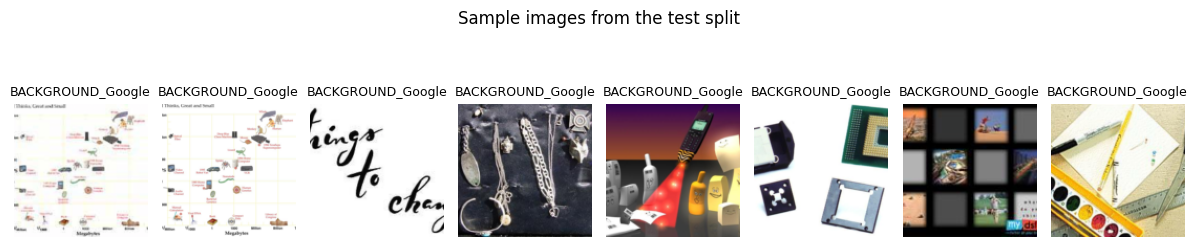

In [18]:
def unnormalize(img, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    img = img.clone()
    for c, (m, s) in enumerate(zip(mean, std)):
        img[c] = img[c] * s + m
    return img.clamp(0, 1)

xb, yb = next(iter(test_loader))
k = min(8, xb.size(0))

plt.figure(figsize=(12, 3))
for i in range(k):
    img_disp = unnormalize(xb[i]).permute(1, 2, 0).numpy()
    plt.subplot(1, k, i + 1)
    plt.imshow(img_disp)
    plt.title(class_names[yb[i].item()], fontsize=9)
    plt.axis("off")
plt.suptitle("Sample images from the test split", fontsize=12)
plt.tight_layout()
plt.show()

### **Comparing Predictions Across Models**

We will now run **side-by-side inference** on a small batch of test images using our three models:

- **Pretrained baseline** (ImageNet backbone + 10-class head, untrained)  
- **Feature-extracted** (NB02: frozen backbone, trained head)  
- **Fine-tuned** (NB03: `layer4` + head trained with small LR)

This qualitative view helps us see which model **generalizes** better and which one **confuses** classes.  
Typically, the **fine-tuned** model is more confident on harder examples, while the **feature-extracted** model remains a very strong baseline.  
The **pretrained baseline** (with an untrained head) often produces near-random predictions and serves only as a reference point.

In [20]:
# Paths
CKPT = Path("/content/drive/MyDrive/checkpoints")
CKPT_FE = CKPT / "resnet18_feature_extraction.pth"
CKPT_FT = CKPT / "resnet18_finetuned.pth"
CKPT_PRE = CKPT / "resnet18_pretrained.pth"
CKPT_INIT = CKPT / "resnet18_frozen_init.pth"
num_classes = len(class_names)

def make_resnet18(num_classes: int, weights="IMAGENET1K_V1"):
    m = models.resnet18(weights=getattr(models.ResNet18_Weights, weights) if isinstance(weights, str) else weights)
    in_f = m.fc.in_features
    m.fc = nn.Linear(in_f, num_classes)
    return m

# --- Pretrained baseline:
if CKPT_PRE.exists():
    model_pretrained = make_resnet18(num_classes, "IMAGENET1K_V1")
    model_pretrained.load_state_dict(torch.load(CKPT_PRE, weights_only=False, map_location="cpu"), strict=True)
    baseline_name = "pretrained.pth"
elif CKPT_INIT.exists():
    model_pretrained = make_resnet18(num_classes, "IMAGENET1K_V1")
    model_pretrained.load_state_dict(torch.load(CKPT_INIT, weights_only=False, map_location="cpu"), strict=True)
    baseline_name = "frozen_init.pth"
else:
    model_pretrained = make_resnet18(num_classes, "IMAGENET1K_V1")  # random 10-class head
    baseline_name = "ImageNet backbone + random 10-cls head"

model_pretrained = model_pretrained.to(device).eval()

# Feature extraction model
assert CKPT_FE.exists(), f"Missing NB02 checkpoint: {CKPT_FE}"
model_feature = make_resnet18(num_classes, "IMAGENET1K_V1")
model_feature.load_state_dict(torch.load(CKPT_FE, weights_only=False, map_location="cpu"), strict=True)
# emulate FE inference
for p in model_feature.parameters(): p.requires_grad = False
model_feature = model_feature.to(device).eval()

# Fine-tuned model
assert CKPT_FT.exists(), f"Missing NB03 checkpoint: {CKPT_FT}"
model_finetuned = make_resnet18(num_classes, "IMAGENET1K_V1")
model_finetuned.load_state_dict(torch.load(CKPT_FT, weights_only=False, map_location="cpu"), strict=True)
model_finetuned = model_finetuned.to(device).eval()

print("[ok] Loaded models:")
print(f"  - Baseline: {baseline_name}")
print(f"  - Feature-extracted: {CKPT_FE.name}")
print(f"  - Fine-tuned:        {CKPT_FT.name}")


[ok] Loaded models:
  - Baseline: frozen_init.pth
  - Feature-extracted: resnet18_feature_extraction.pth
  - Fine-tuned:        resnet18_finetuned.pth


**Inference helpers and batch predictions**

In [21]:
@torch.no_grad()
def predict_batch(model, xb):
    logits = model(xb.to(device))
    probs = F.softmax(logits, dim=1).cpu().numpy()
    pred_idx = probs.argmax(axis=1)
    conf = probs.max(axis=1)
    return pred_idx, conf

# get one batch
xb, yb = next(iter(test_loader))
xb_dev = xb.to(device)

pred_pre, conf_pre = predict_batch(model_pretrained, xb)
pred_fe,  conf_fe  = predict_batch(model_feature,   xb)
pred_ft,  conf_ft  = predict_batch(model_finetuned, xb)

y_true = yb.numpy()

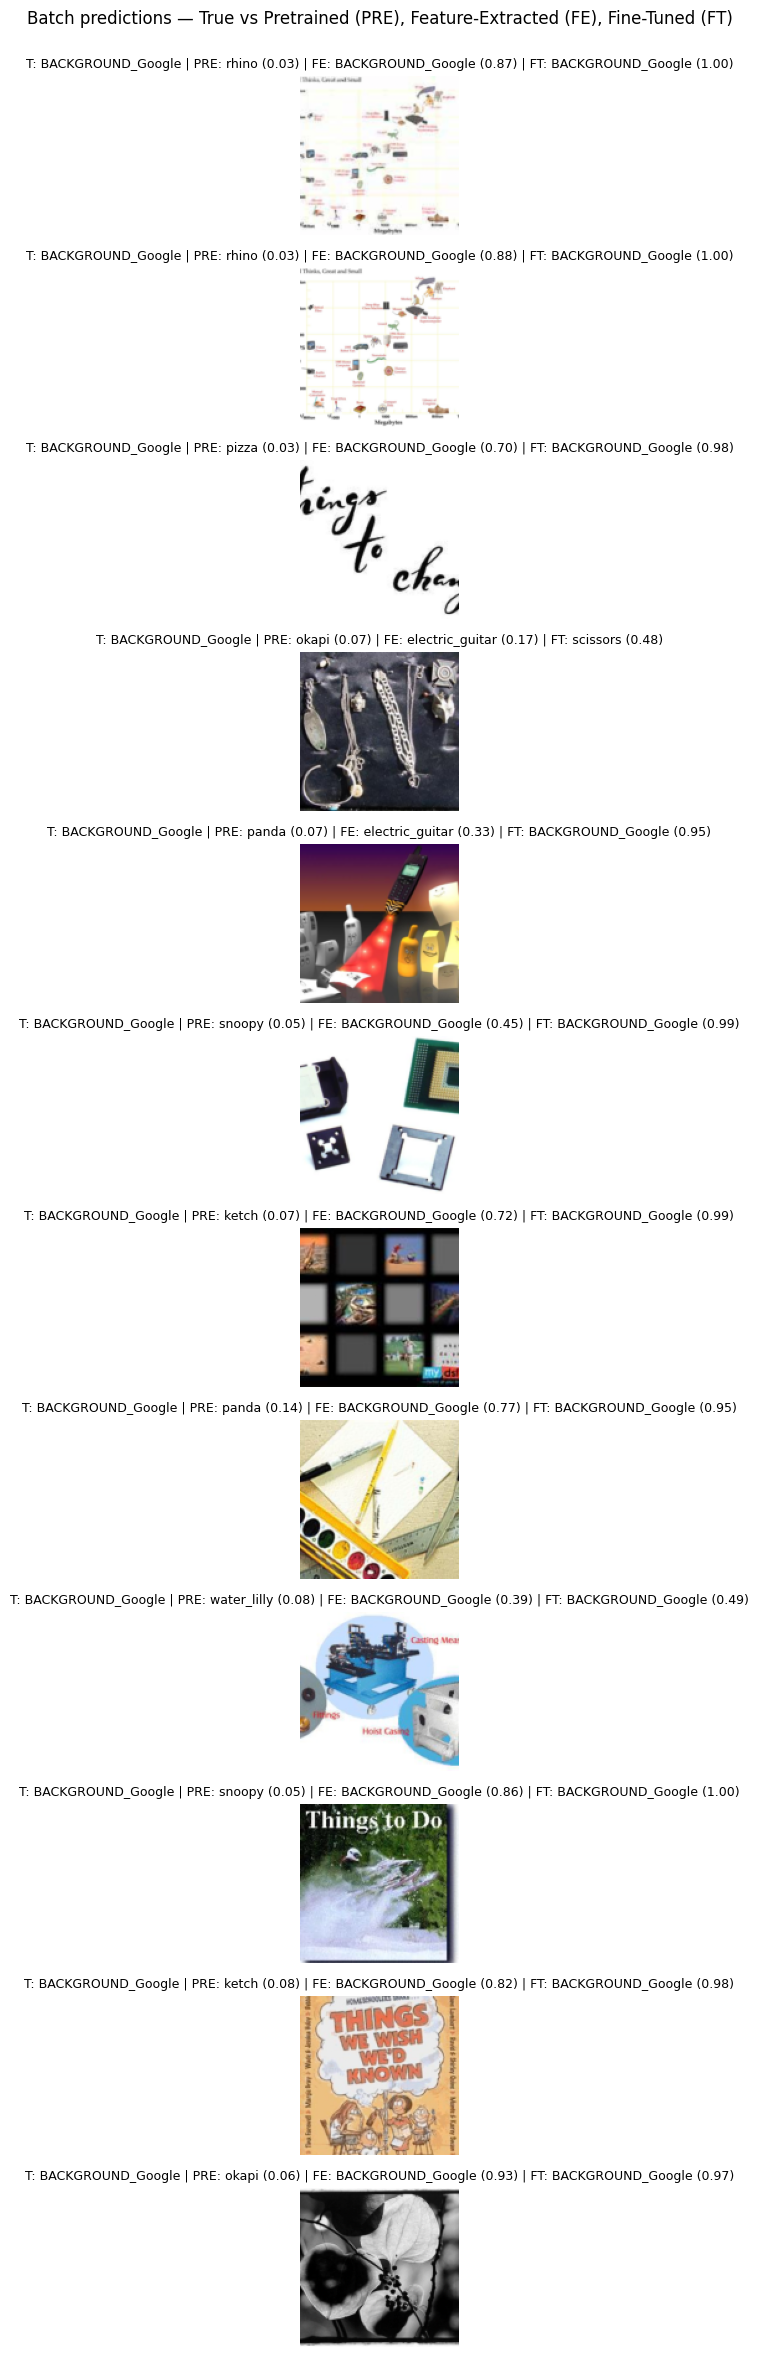

In [22]:
def unnormalize(img_tensor, mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]):
    t = img_tensor.clone()
    for c,(m,s) in enumerate(zip(mean,std)):
        t[c] = t[c]*s + m
    return t.clamp(0,1)

k = min(12, xb.size(0))
cols = 3  # show 3 columns per row (we'll stack rows)
rows = k

plt.figure(figsize=(10, rows * 2.0))
for i in range(k):
    img = unnormalize(xb[i]).permute(1,2,0).numpy()
    t_lbl  = class_names[y_true[i]]
    p_pre  = class_names[pred_pre[i]]
    p_fe   = class_names[pred_fe[i]]
    p_ft   = class_names[pred_ft[i]]

    # one row per image with 1 big panel
    ax = plt.subplot(rows, 1, i+1)
    ax.imshow(img)
    title = (
        f"T: {t_lbl} | "
        f"PRE: {p_pre} ({conf_pre[i]:.2f}) | "
        f"FE: {p_fe} ({conf_fe[i]:.2f}) | "
        f"FT: {p_ft} ({conf_ft[i]:.2f})"
    )
    ax.set_title(title, fontsize=9)
    ax.axis("off")

plt.suptitle("Batch predictions — True vs Pretrained (PRE), Feature-Extracted (FE), Fine-Tuned (FT)", fontsize=12)
plt.tight_layout(rect=[0,0,1,0.98])
plt.show()


**Compact tabular comparison for the same batch**

In [23]:
rows = []
for i in range(k):
    rows.append({
        "true": class_names[y_true[i]],
        "PRE_pred": class_names[pred_pre[i]],
        "PRE_conf": f"{conf_pre[i]:.2f}",
        "FE_pred":  class_names[pred_fe[i]],
        "FE_conf":  f"{conf_fe[i]:.2f}",
        "FT_pred":  class_names[pred_ft[i]],
        "FT_conf":  f"{conf_ft[i]:.2f}",
    })

pd.DataFrame(rows)

,true,PRE_pred,PRE_conf,FE_pred,FE_conf,FT_pred,FT_conf
0,BACKGROUND_Google,rhino,0.03,BACKGROUND_Google,0.87,BACKGROUND_Google,1.00
1,BACKGROUND_Google,rhino,0.03,BACKGROUND_Google,0.88,BACKGROUND_Google,1.00
2,BACKGROUND_Google,pizza,0.03,BACKGROUND_Google,0.70,BACKGROUND_Google,0.98
3,BACKGROUND_Google,okapi,0.07,electric_guitar,0.17,scissors,0.48
4,BACKGROUND_Google,panda,0.07,electric_guitar,0.33,BACKGROUND_Google,0.95
5,BACKGROUND_Google,snoopy,0.05,BACKGROUND_Google,0.45,BACKGROUND_Google,0.99
6,BACKGROUND_Google,ketch,0.07,BACKGROUND_Google,0.72,BACKGROUND_Google,0.99
7,BACKGROUND_Google,panda,0.14,BACKGROUND_Google,0.77,BACKGROUND_Google,0.95
8,BACKGROUND_Google,water_lilly,0.08,BACKGROUND_Google,0.39,BACKGROUND_Google,0.49
9,BACKGROUND_Google,snoopy,0.05,BACKGROUND_Google,0.86,BACKGROUND_Google,1.00


**Interpretation**

 - The **pretrained baseline** (untrained 10-class head) often behaves **near-randomly** and may assign **confident but incorrect** labels — this is expected since its head is not trained.  
 - The **feature-extracted** model is usually **strong and stable**, leveraging robust pretrained features with a task-specific head.  
 - The **fine-tuned** model often shows **higher confidence** and **fewer confusions** on challenging images, especially where Caltech textures or shapes diverge from ImageNet’s.

### **Quantitative Evaluation**

For each model, we will compute:
- **Accuracy** – overall correctness of predictions.
- **Precision**, **Recall**, and **F1-score** (both *macro* and *weighted* averages).
- **Confusion matrix**, to visualize class-specific strengths and weaknesses.


In [26]:
def evaluate_model(model, loader, name):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb).argmax(1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(yb.cpu().numpy())
    all_preds, all_labels = np.array(all_preds), np.array(all_labels)

    acc = accuracy_score(all_labels, all_preds)
    prec, rec, f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average=None, zero_division=0
    )
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="macro", zero_division=0
    )
    prec_weight, rec_weight, f1_weight, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="weighted", zero_division=0
    )
    cm = confusion_matrix(all_labels, all_preds)
    return {
        "name": name,
        "acc": acc,
        "prec_macro": prec_macro,
        "rec_macro": rec_macro,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weight,
        "cm": cm
    }

results = []
for name, model in [
    ("Pretrained", model_pretrained),
    ("Feature-Extracted", model_feature),
    ("Fine-Tuned", model_finetuned)
]:
    print(f"Evaluating {name}...")
    res = evaluate_model(model, test_loader, name)
    results.append(res)
    print(f"{name} done.")


Evaluating Pretrained...
Pretrained done.
Evaluating Feature-Extracted...
Feature-Extracted done.
Evaluating Fine-Tuned...
Fine-Tuned done.


**Display comparative metrics table**

In [27]:
df_metrics = pd.DataFrame([{
    "Model": r["name"],
    "Accuracy": f"{r['acc']*100:.2f}%",
    "F1 (Macro)": f"{r['f1_macro']*100:.2f}%",
    "F1 (Weighted)": f"{r['f1_weighted']*100:.2f}%"
} for r in results])

display(df_metrics)

,Model,Accuracy,F1 (Macro),F1 (Weighted)
0,Pretrained,0.55%,0.41%,0.50%
1,Feature-Extracted,93.18%,92.42%,93.18%
2,Fine-Tuned,93.79%,92.30%,93.76%


**Visualize confusion matrices side-by-side**

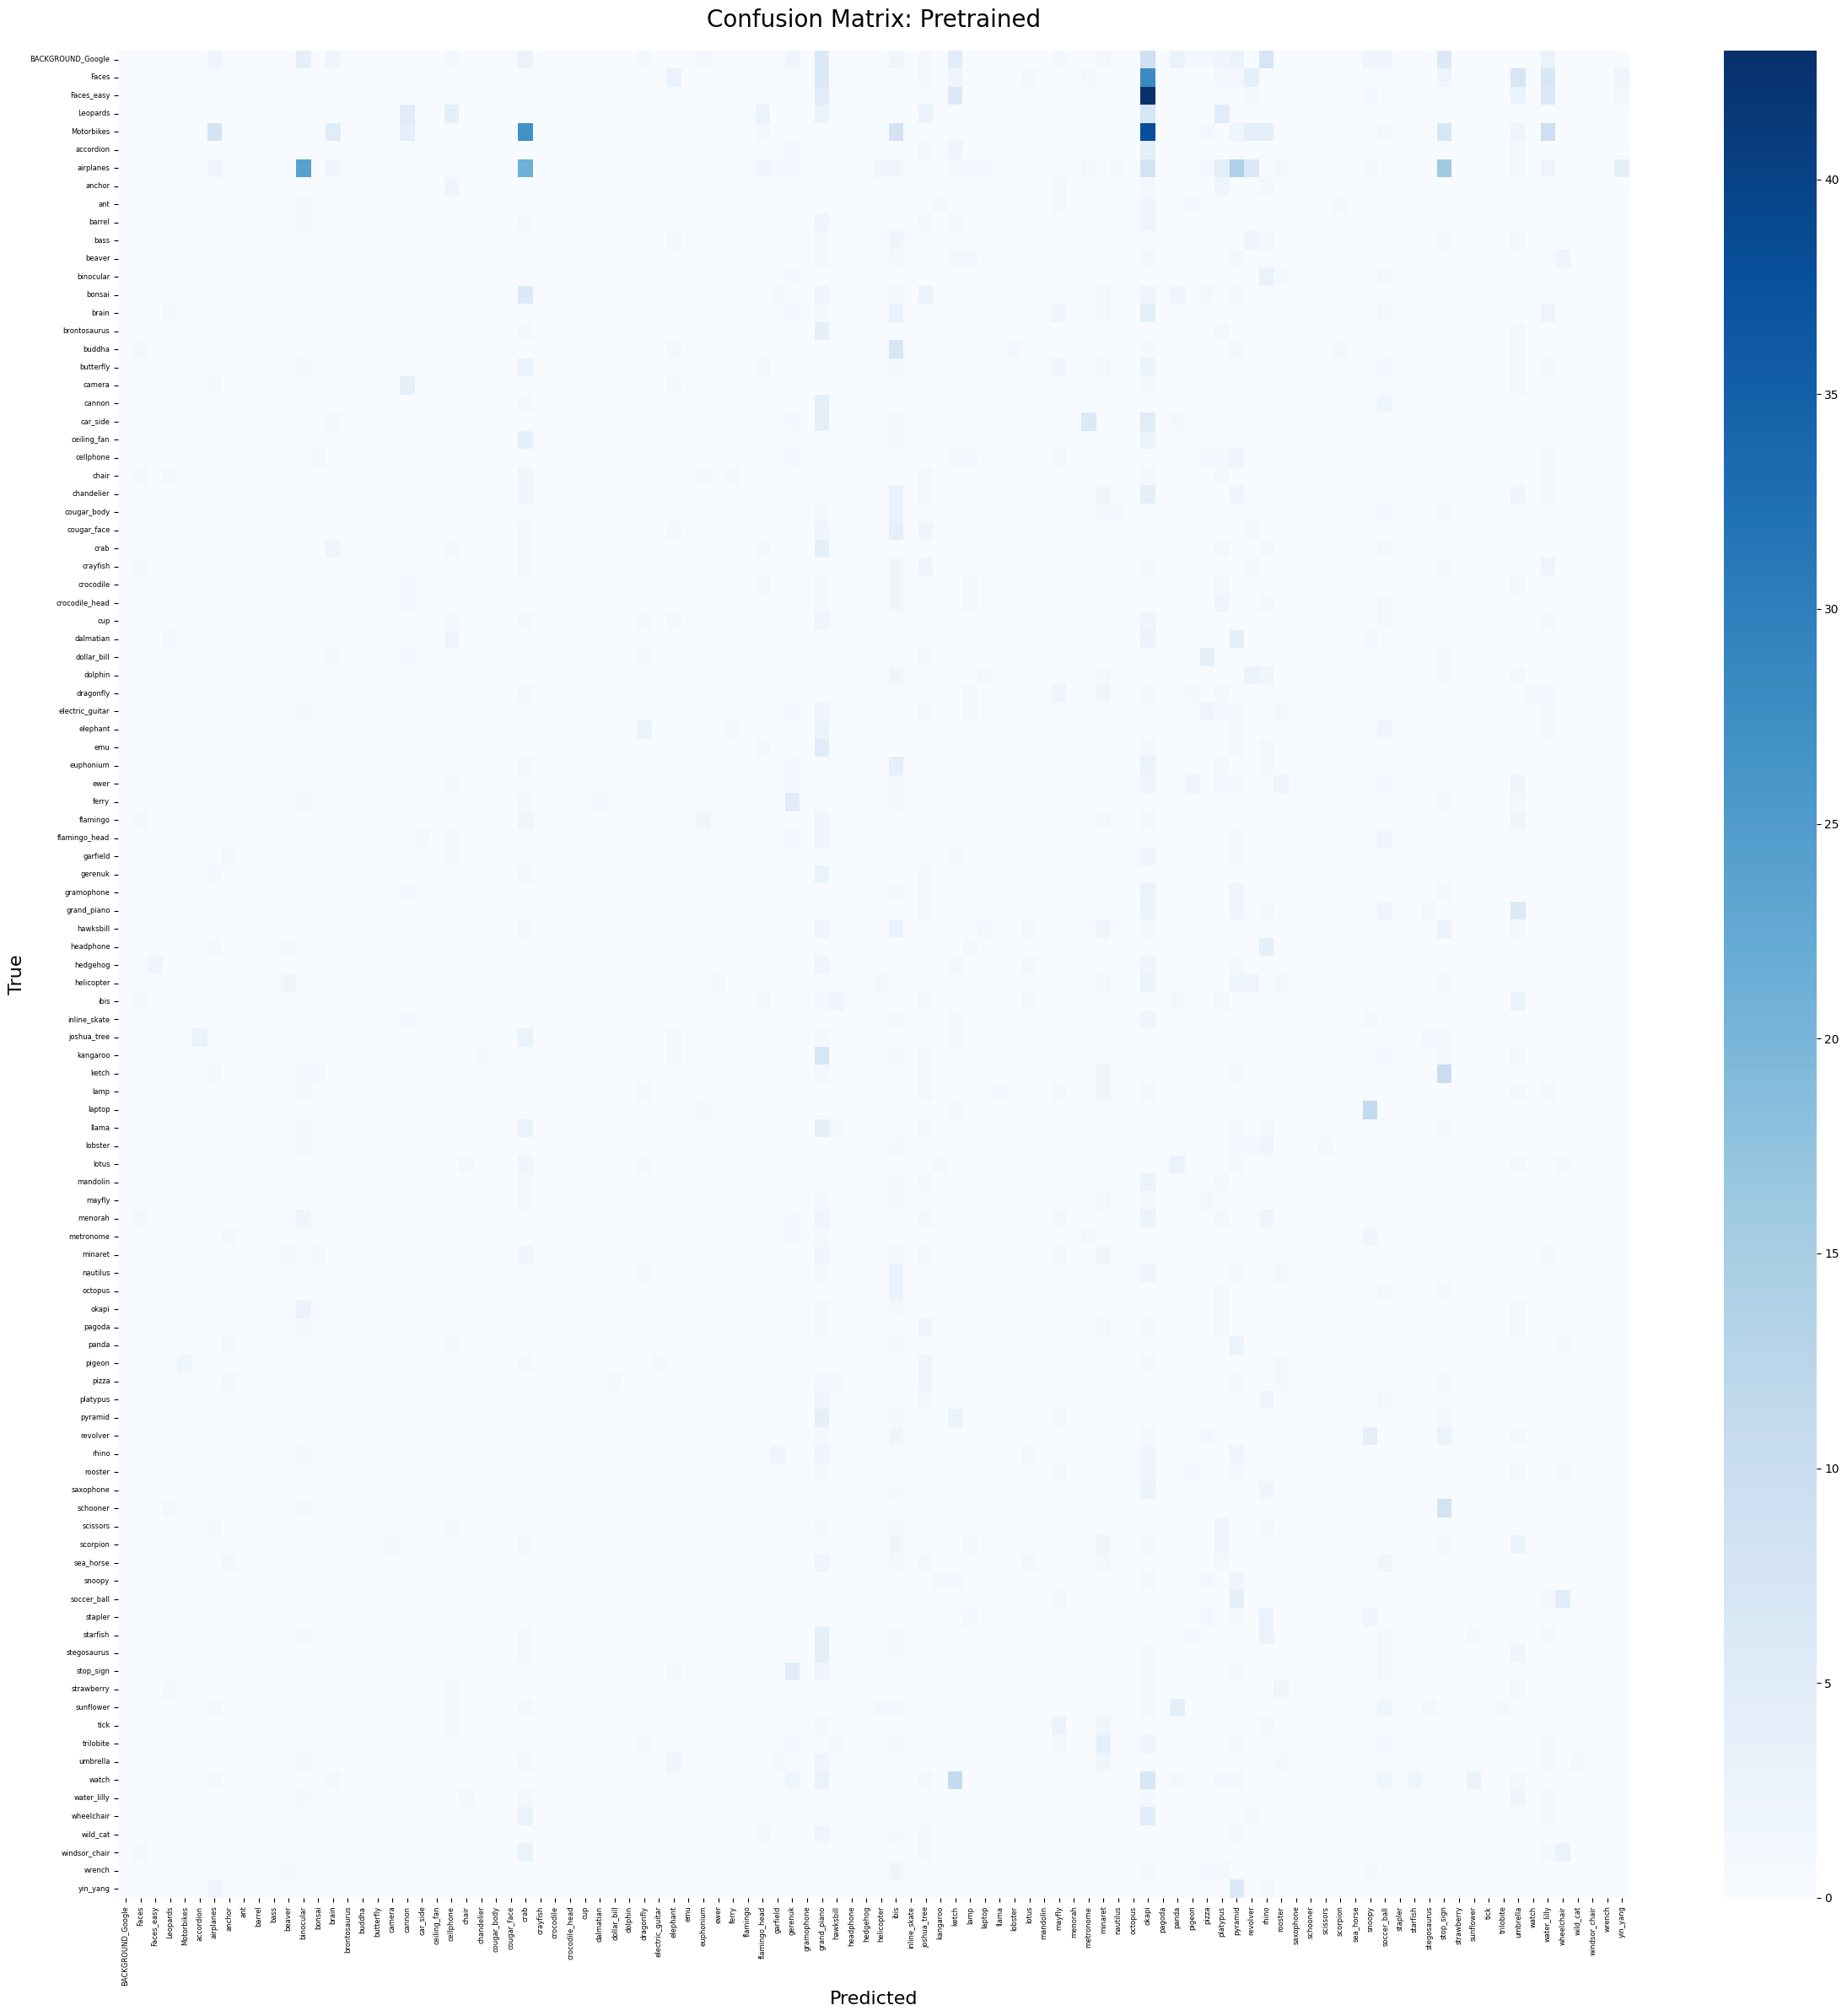

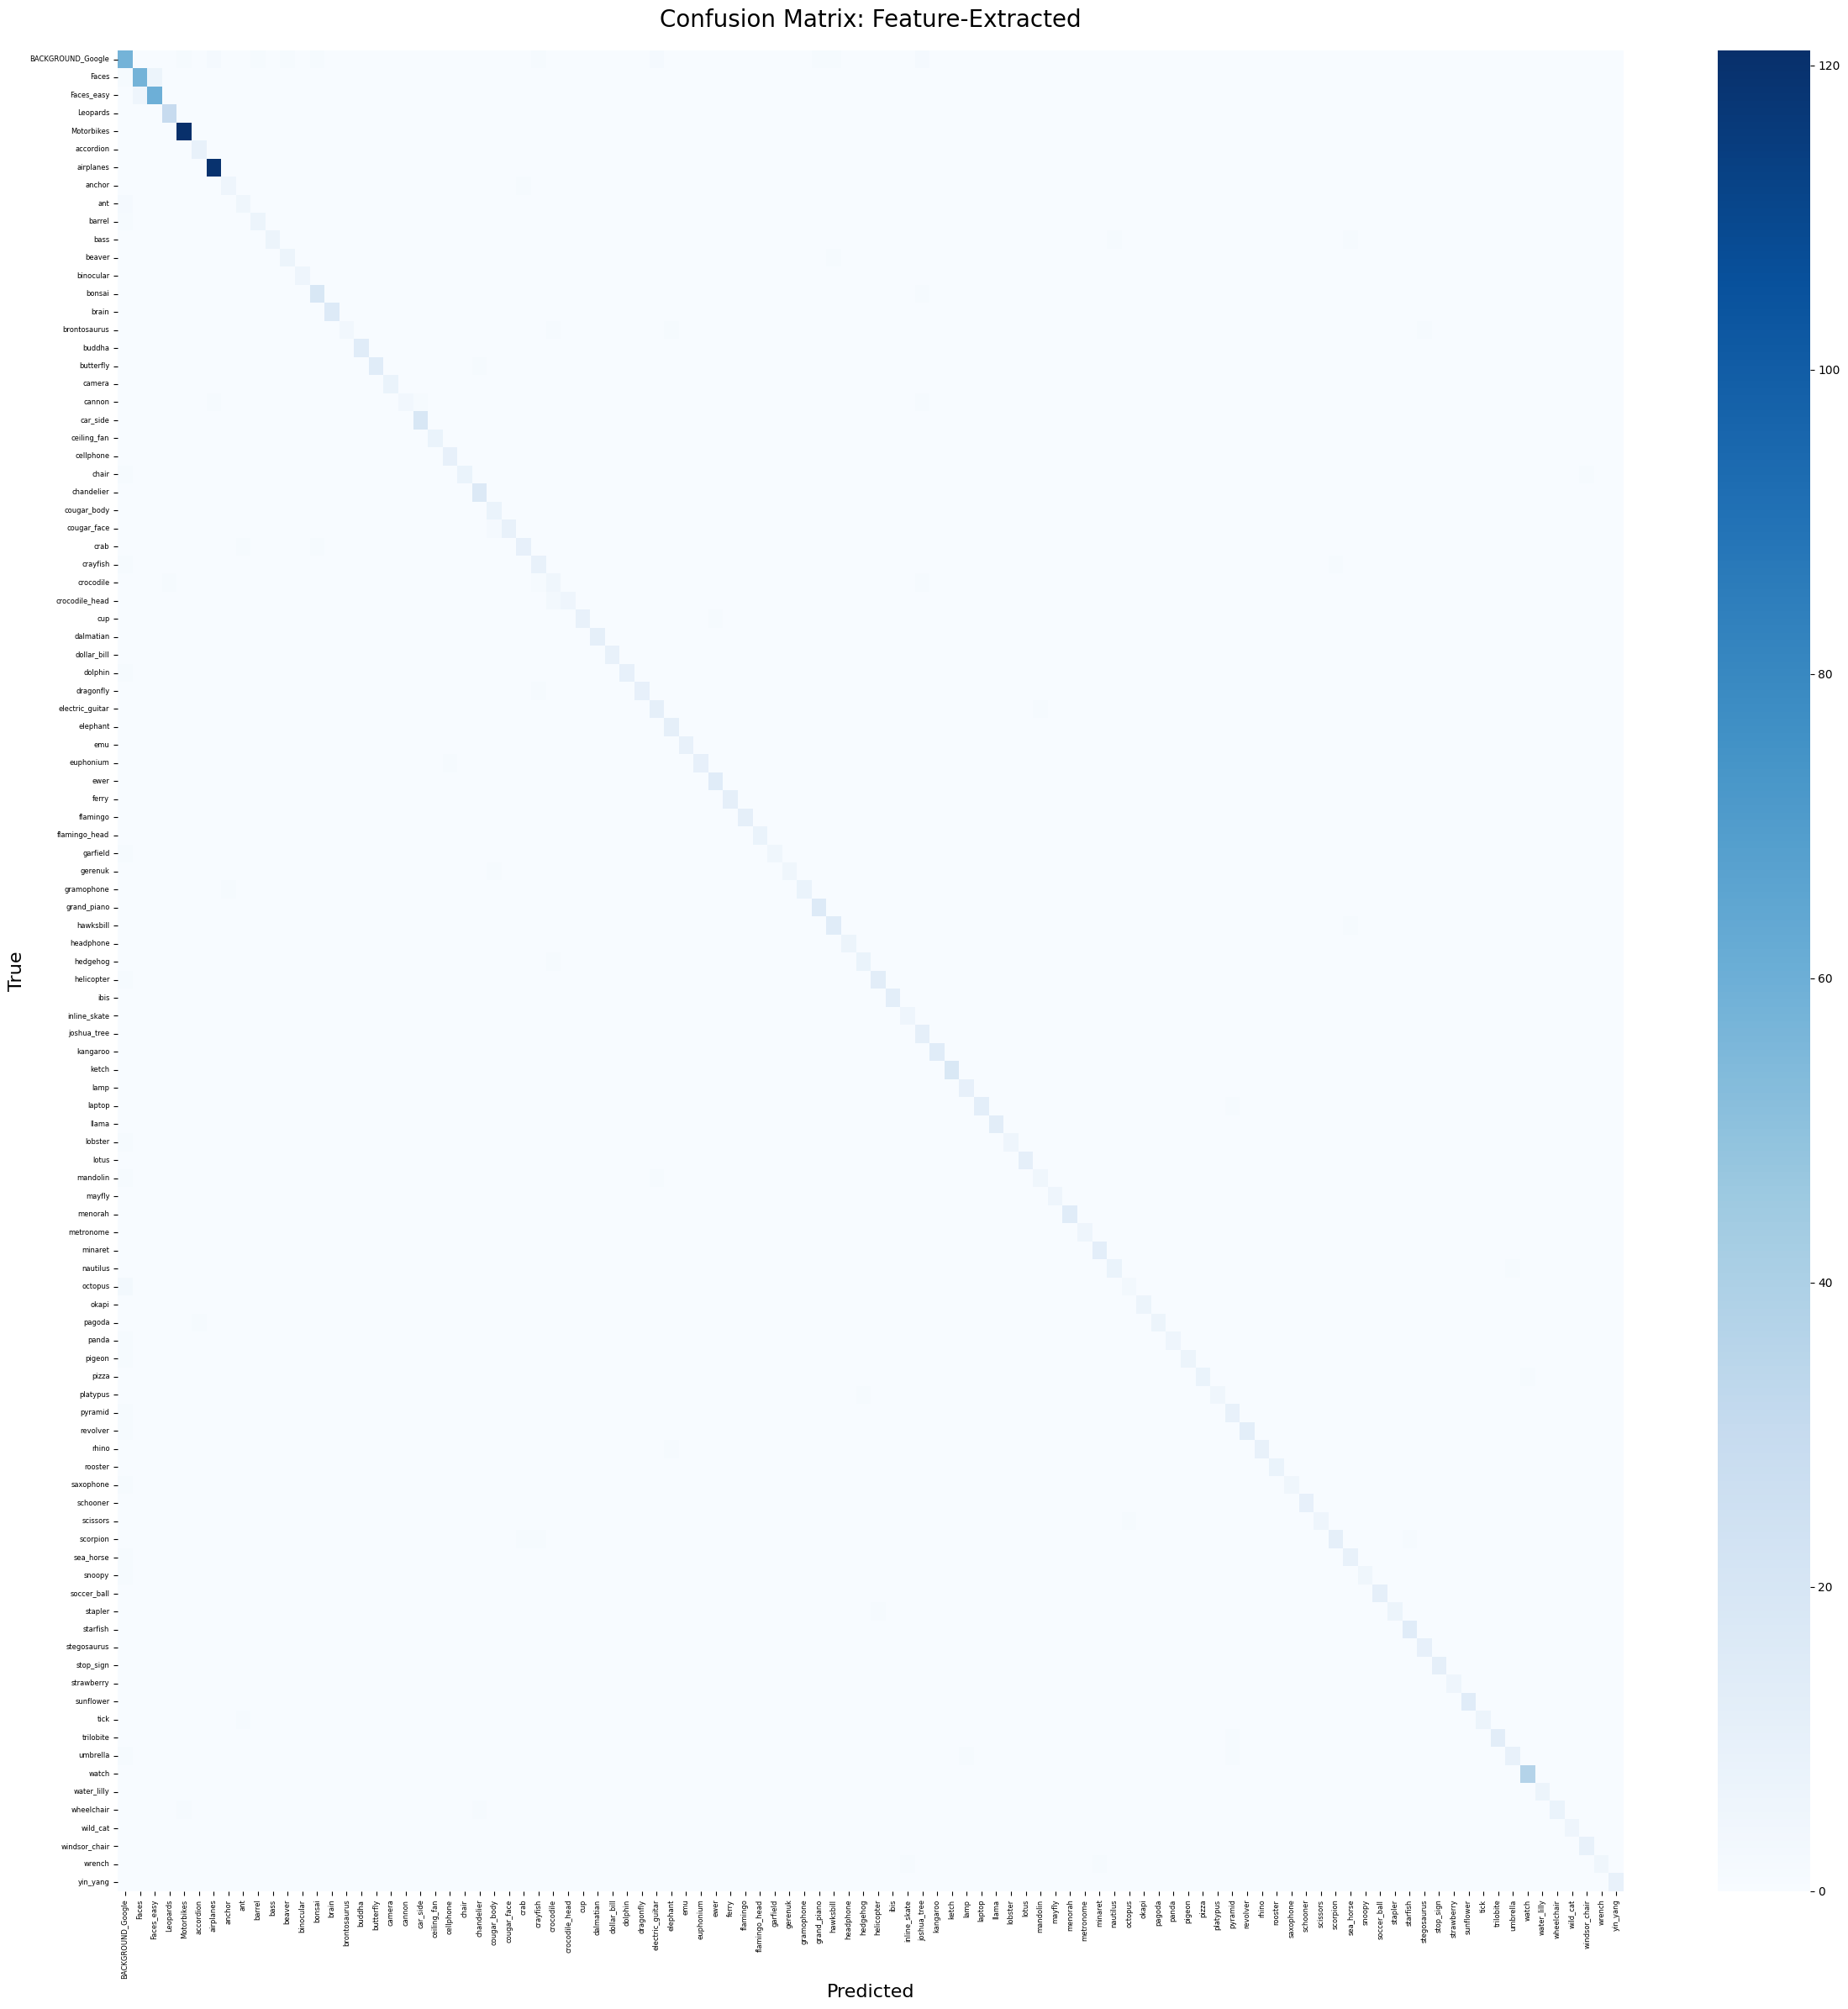

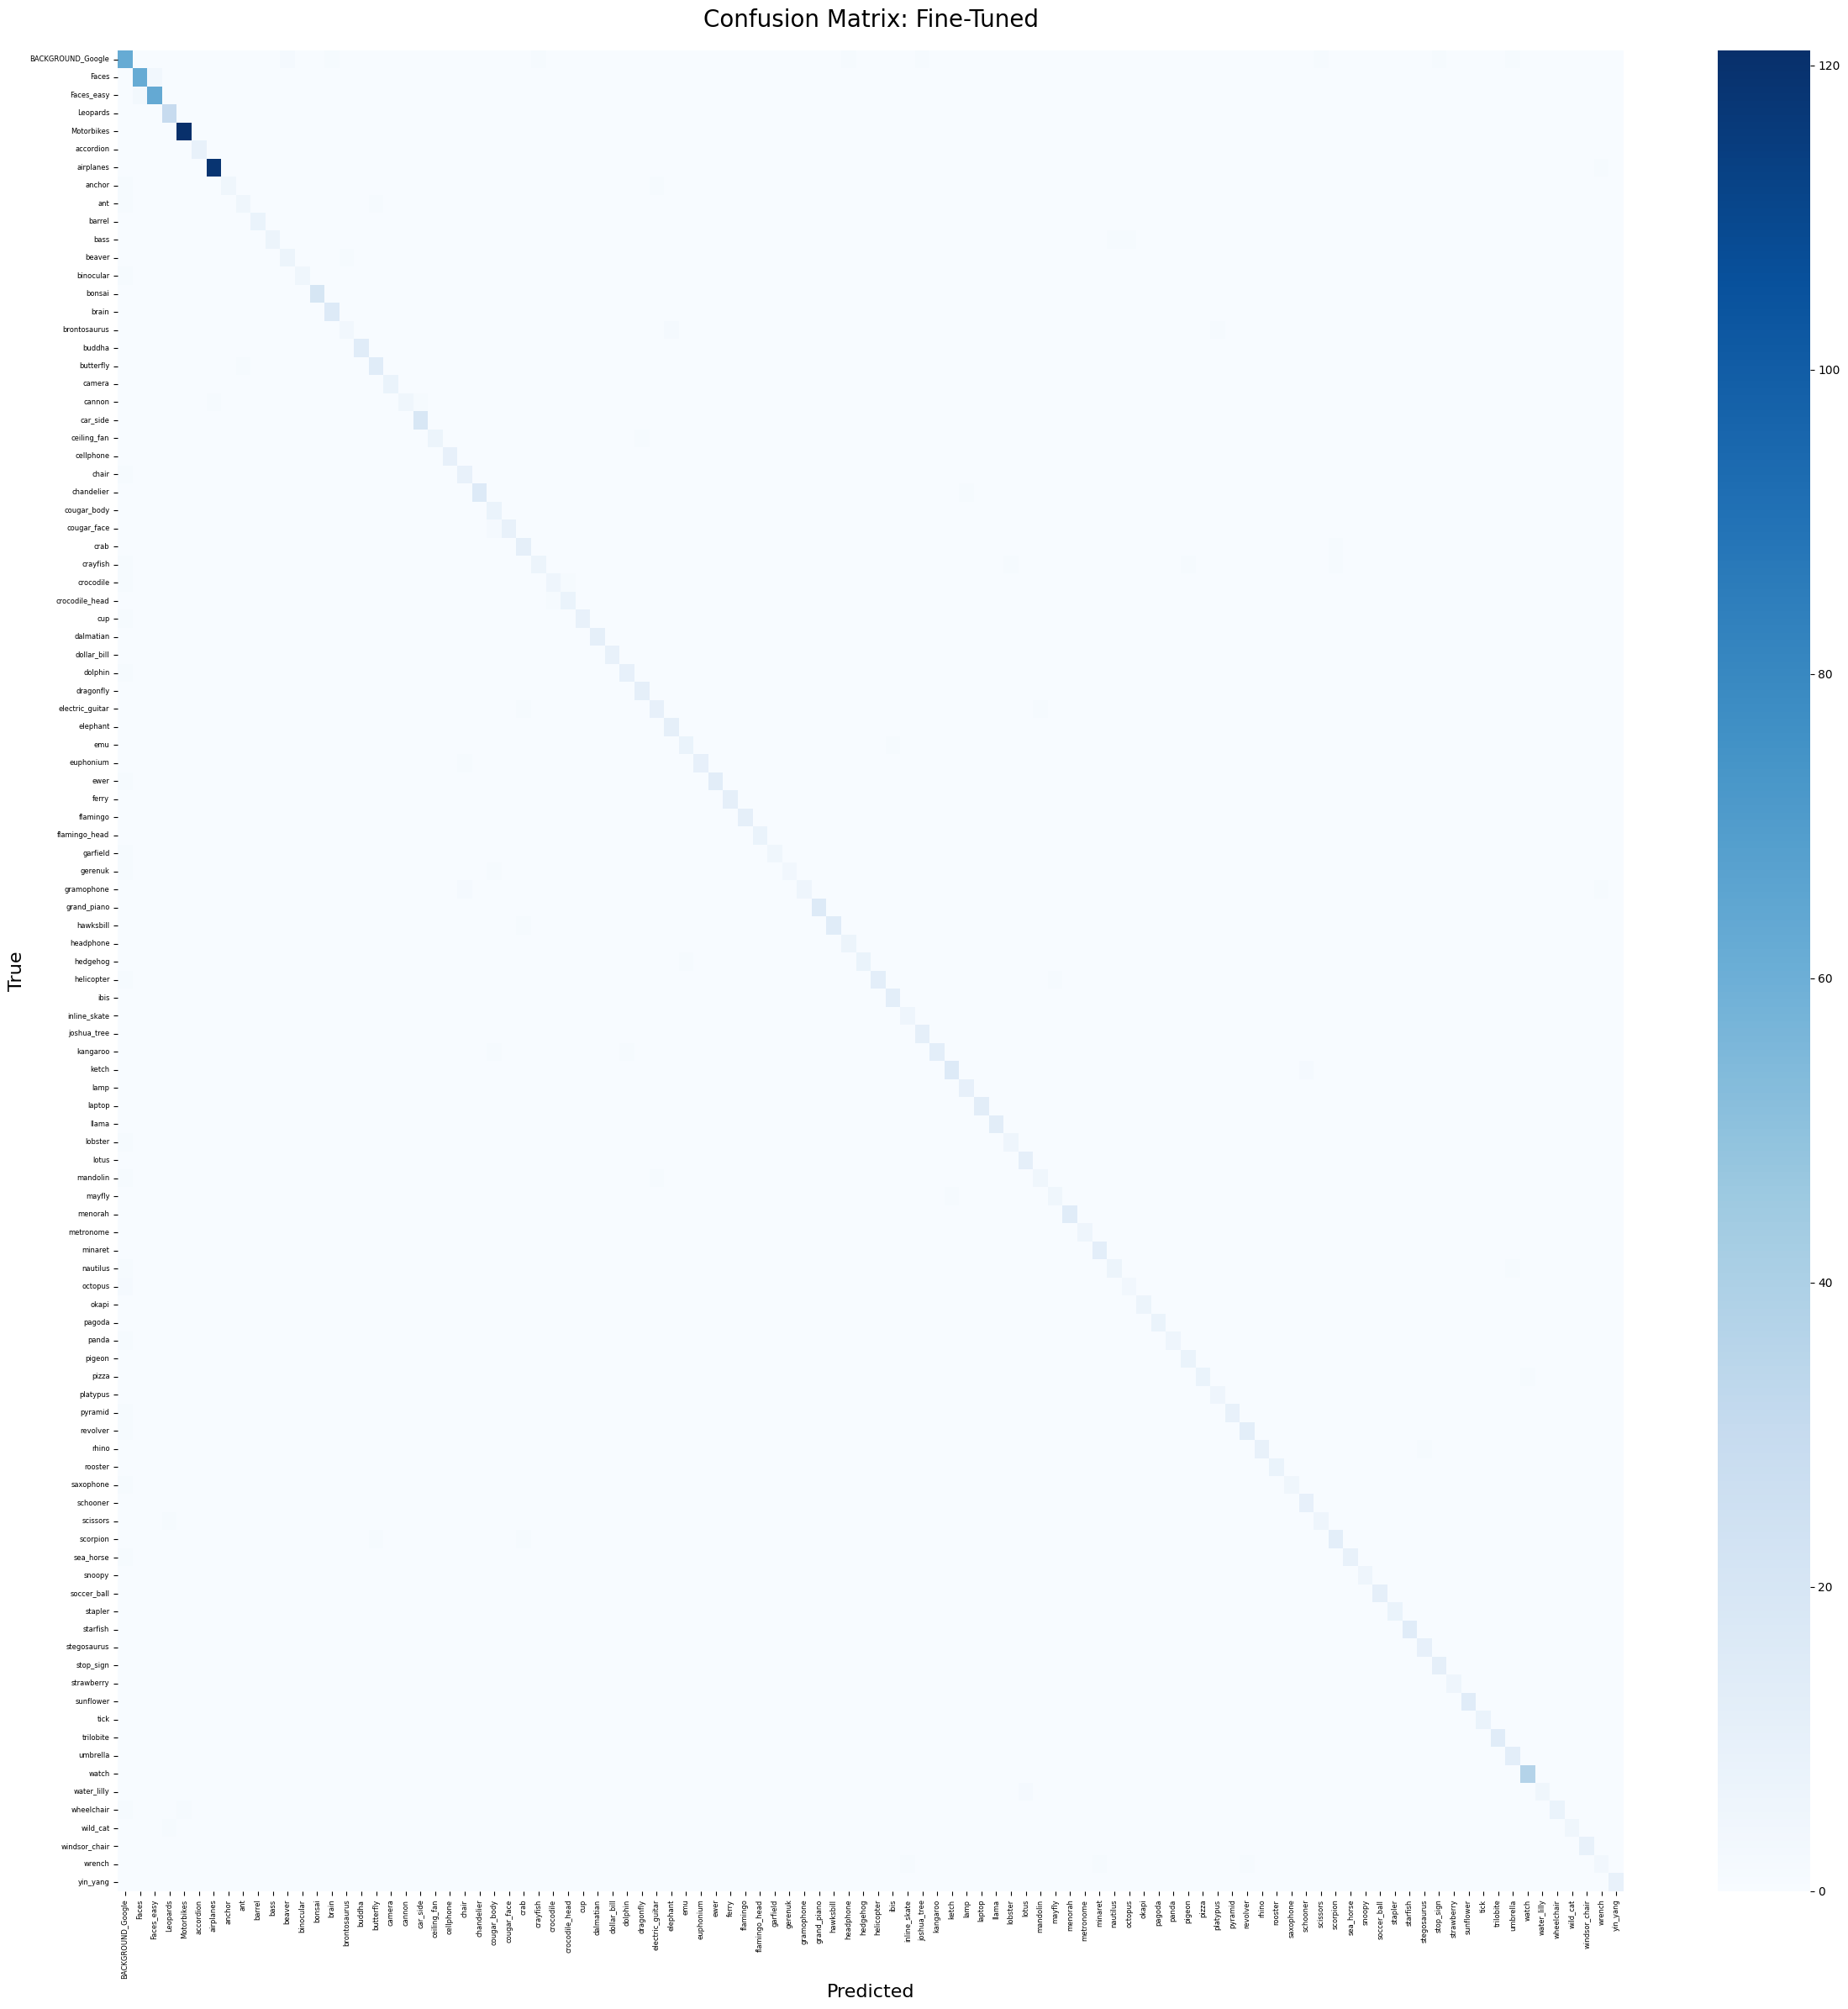

In [31]:
for r in results:
    cm = r["cm"]
    name = r["name"]
    plt.figure(figsize=(24, 24))

    ax = sns.heatmap(cm, annot=False, cmap="Blues")

    ax.set_title(f"Confusion Matrix: {name}", fontsize=20, pad=20)
    ax.set_xlabel("Predicted", fontsize=16)
    ax.set_ylabel("True", fontsize=16)

    ax.set_xticks(np.arange(len(class_names)) + 0.5)
    ax.set_xticklabels(class_names, rotation=90, fontsize=6)

    ax.set_yticks(np.arange(len(class_names)) + 0.5)
    ax.set_yticklabels(class_names, rotation=0, fontsize=6)

    plt.tight_layout()
    plt.show()

### ** Visualizing Feature Maps and Activations**

To **see** what changes across our three transfer-learning stages, we will peek inside the networks:

- **Pretrained (baseline)**: generic features learned from ImageNet — edges, textures, shapes.  
- **Feature-extracted (NB02)**: reuses those features **as-is**; the classifier head learns a new mapping.  
- **Fine-tuned (NB03)**: adjusts deeper features (e.g., `layer4`) to become **more class-specific** for our 10 Caltech classes.

We will:
- Capture **activation maps** from `layer4` for the **same image** across all three models.  
- Reduce channel dimension by a simple mean to obtain an interpretable 2D map.  
- Optionally compute **Grad-CAM** overlays to visualize *where* each model is looking for its prediction.

**Capture layer4 activations for one image (all three models)**

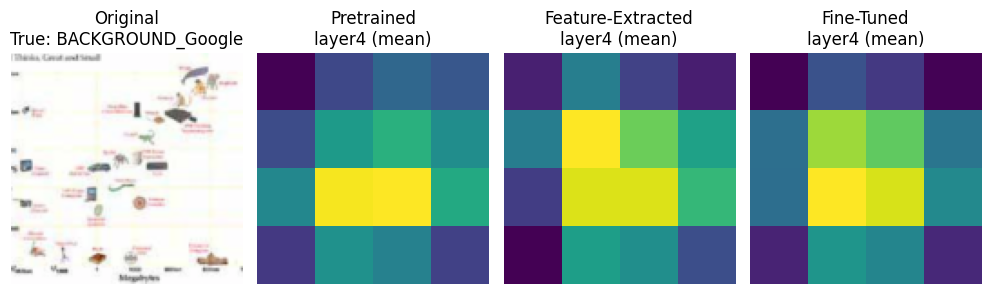

In [33]:
import torch
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

# Get a single sample from test set
xb, yb = next(iter(test_loader))
img = xb[0:1].to(device)     # shape [1,3,H,W]
true_idx = yb[0].item()
true_cls = class_names[true_idx]

# Hook to capture layer4 activations
def capture_layer4_activations(model, x):
    acts = {}
    handle = model.layer4.register_forward_hook(lambda m, i, o: acts.setdefault("a", o.detach().cpu()))
    with torch.no_grad():
        _ = model(x)
    handle.remove()
    # acts["a"] ⇒ [1, C, H, W] → mean over C ⇒ [H, W]
    a = acts["a"][0].mean(dim=0)
    # normalize to 0..1 for visualization
    a = a - a.min()
    a = a / a.max().clamp(min=1e-8)
    return a.numpy()

act_pre = capture_layer4_activations(model_pretrained, img)
act_fe  = capture_layer4_activations(model_feature,   img)
act_ft  = capture_layer4_activations(model_finetuned, img)

# Show original image and activation maps
def unnormalize_for_vis(x, mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]):
    x = x[0].detach().cpu().clone()
    for c,(m,s) in enumerate(zip(mean,std)):
        x[c] = x[c]*s + m
    return x.clamp(0,1).permute(1,2,0).numpy()

orig = unnormalize_for_vis(img)

plt.figure(figsize=(10,3))
plt.subplot(1,4,1)
plt.imshow(orig)
plt.title(f"Original\nTrue: {true_cls}")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(act_pre, cmap="viridis")
plt.title("Pretrained\nlayer4 (mean)")
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(act_fe, cmap="viridis")
plt.title("Feature-Extracted\nlayer4 (mean)")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(act_ft, cmap="viridis")
plt.title("Fine-Tuned\nlayer4 (mean)")
plt.axis("off")

plt.tight_layout()
plt.show()


**Grad-CAM overlays for the same image (all three models)**

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:1870: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)
/tmp/ipykernel_1558/534336405.py:68: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  heat = cm.get_cmap(cmap)(cam)[..., :3]   # RGBA -> RGB


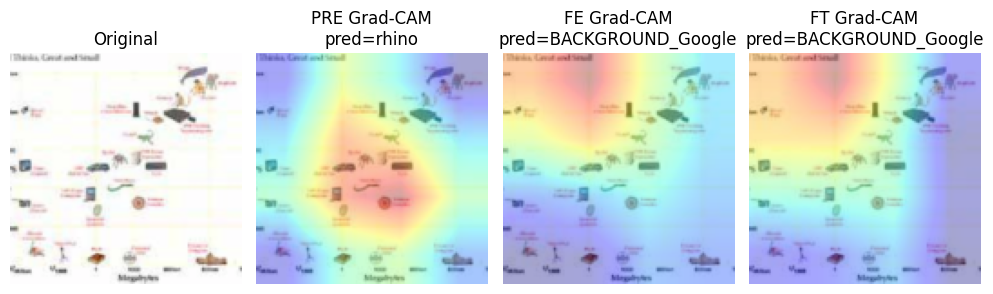

In [35]:
from matplotlib import cm

def gradcam(model, x, target_layer):
    """
    Compute Grad-CAM heatmap [H, W] in 0..1 for the model's predicted class.
    Works for pretrained, feature-extraction, and fine-tuned models.
    """
    model.eval()
    acts, grads = {}, {}

    # Forward hook: save activations of target_layer
    def fwd_hook(_m, _i, o):
        acts["a"] = o

    # Backward hook: save gradient w.r.t. those activations
    def bwd_hook(_m, grad_in, grad_out):
        grads["g"] = grad_out[0]

    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_backward_hook(bwd_hook)

    # Use a fresh input that tracks gradients
    x_local = x.clone().detach().requires_grad_(True)

    # Forward pass
    logits = model(x_local)                   # [1, num_classes]
    pred_idx = logits.argmax(dim=1)[0].item() # scalar int

    # Backprop wrt predicted class logit
    score = logits[0, pred_idx]
    model.zero_grad(set_to_none=True)
    score.backward()

    # Remove hooks
    h1.remove()
    h2.remove()

    # Activations & grads: [C, H, W]
    A = acts["a"][0]
    G = grads["g"][0]

    # Channel weights via global average pooling over spatial dims
    weights = G.mean(dim=(1, 2), keepdim=True)   # [C,1,1]
    cam = (weights * A).sum(dim=0)              # [H,W]

    # Standard Grad-CAM: ReLU + normalize to [0,1]
    cam = torch.relu(cam).detach().cpu()
    cam = cam - cam.min()
    cam = cam / cam.max().clamp(min=1e-8)

    return cam.numpy(), pred_idx

# --- Overlay utility with CAM upsampling ---

def overlay_cam(rgb, cam, alpha=0.35, cmap="jet"):
    """
    rgb: (H, W, 3) in [0,1]
    cam: (h, w) in [0,1] from Grad-CAM
    """
    H, W = rgb.shape[:2]

    # Resize CAM to image size if needed
    if cam.shape != (H, W):
        cam_t = torch.from_numpy(cam).float().unsqueeze(0).unsqueeze(0)  # [1,1,h,w]
        cam_t = F.interpolate(cam_t, size=(H, W), mode="bilinear", align_corners=False)
        cam = cam_t.squeeze().cpu().numpy()  # [H,W]

    heat = cm.get_cmap(cmap)(cam)[..., :3]   # RGBA -> RGB
    return (1 - alpha) * rgb + alpha * heat

# --- Compute Grad-CAM for each model at layer4 ---

cam_pre, p_pre = gradcam(model_pretrained, img, model_pretrained.layer4)
cam_fe,  p_fe  = gradcam(model_feature,   img, model_feature.layer4)
cam_ft,  p_ft  = gradcam(model_finetuned, img, model_finetuned.layer4)

# rgb is the original unnormalized image: [H, W, 3] in [0,1]
rgb   = orig
ov_pre = overlay_cam(rgb, cam_pre)
ov_fe  = overlay_cam(rgb, cam_fe)
ov_ft  = overlay_cam(rgb, cam_ft)

# --- Plot ---

plt.figure(figsize=(10, 3))

plt.subplot(1, 4, 1)
plt.imshow(rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(ov_pre)
plt.title(f"PRE Grad-CAM\npred={class_names[p_pre]}")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(ov_fe)
plt.title(f"FE Grad-CAM\npred={class_names[p_fe]}")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(ov_ft)
plt.title(f"FT Grad-CAM\npred={class_names[p_ft]}")
plt.axis("off")

plt.tight_layout()
plt.show()


**How to Read These Visuals**

- **Activation maps (mean over channels)**  
  These show **where** the `layer4` feature energy is concentrated.  
  - In the **pretrained** model, patterns tend to be **generic** — edges, textures, and object-like regions.  
  - In the **feature-extracted** model, the maps look **similar** to the pretrained ones (backbone unchanged).  
  - In the **fine-tuned** model, we expect **sharper focus** on the object or its distinctive parts, indicating **specialization**.

- **Grad-CAM overlays**  
  These highlight **spatial regions** most responsible for the model’s predicted class.  
  - After fine-tuning, attention often shifts **away from background** and **toward** object regions (e.g., outlines, textures, key parts).  
  - If the **prediction improves** from FE → FT, check whether the FT heatmap better aligns with the **true object**.